# Gridded exponential-galaxy skyCatalog for imSim

Build a grid of **simple exponential galaxies** (single Sersic n=1 disk each) as a
[skyCatalog](https://lsstdesc.org/skyCatalogs/usage_read.html) that
[imSim](https://github.com/LSSTDESC/imSim) can ingest unmodified via its `sky_catalog` input.

Aimed at **cosmological shear work**: a constant (or drawn) applied shear `(g1, g2)` is injected
into every galaxy (skyCatalogs' `shear_1`/`shear_2` columns, applied via `GalaxyObject._lens`).

**Per-object properties are flexible.** Each of `mag`, `hlr`, `ellipticity`, `pa_deg`, `g1`,
`g2`, and `redshift` may be given as:
* a single **scalar** — the same value for every galaxy,
* a **`scipy.stats` frozen distribution** (e.g. `scipy.stats.norm(loc=20, scale=0.5)`) — an
  independent random draw per galaxy, or
* an explicit **array** of length `n*n` — per-object values in object order.

All random draws share one seeded `numpy` Generator, so a given `seed` reproduces the catalog.

**How it works.** imSim's `SkyCatalogInterface.getObj` only calls three skyCatalogs methods per
object: `get_gsobject_components`, `get_observer_sed_components`, and `get_LSST_flux` (the last
sets the *total* flux, overriding the profile normalization). A galaxy's components are derived
purely from which `sed_val_<bulge|disk|knots>` columns exist, so a parquet with **only
`sed_val_disk`** yields a pure single-component galaxy, and `sersic_disk=1` makes it exponential.

**Environment** (skyCatalogs & imSim are not in the default stack setup):
```bash
source ~/setup_aos_dev.sh
setup -k -r /sdf/home/b/brycek/u/dev-repos/skyCatalogs
setup -k -r /sdf/home/b/brycek/u/dev-repos/imSim
```
then launch Jupyter from that same shell.

> **Shear sign convention (important for shear work):** skyCatalogs applies *intrinsic*
> ellipticity as `Shear(g1=-e1, g2=-e2)` (a cosmoDC2 compatibility flip), so a positive
> `ellipticity_1_disk_true` produces a *negative* observed `e1`. The *applied* shear
> (`shear_1`/`shear_2`) is **not** flipped. Keep this in mind comparing injected vs. recovered.

In [1]:
import os
import subprocess
import glob
import numpy as np
import scipy.stats
import yaml
import healpy as hp
import pyarrow as pa
import pyarrow.parquet as pq
import galsim
import matplotlib.pyplot as plt

from skycatalogs import skyCatalogs
from skycatalogs.objects.base_object import load_lsst_bandpasses

# cosmoDC2-style 30-bin tophat SED definition (start, width) in angstroms,
# taken from skyCatalogs ci_sample/skyCatalog.yaml. The GalaxyObject SED path
# requires it; our SED is flat (all bins equal) and only sets the *shape* --
# the total flux comes from the lsst_flux_* columns.
TOPHAT_BINS = [
    [1000, 246], [1246, 306], [1552, 381], [1933, 474], [2407, 591],
    [2998, 186], [3184, 197], [3381, 209], [3590, 222], [3812, 236],
    [4048, 251], [4299, 266], [4565, 283], [4848, 300], [5148, 319],
    [5467, 339], [5806, 360], [6166, 382], [6548, 406], [6954, 431],
    [7385, 458], [7843, 486], [8329, 517], [8846, 549], [9395, 583],
    [9978, 1489], [11467, 1710], [13177, 1966], [15143, 2259], [17402, 2596],
]
N_TOPHAT = len(TOPHAT_BINS)
COSMOLOGY = {"H0": 71.0, "Ob0": 0.0448, "Om0": 0.2648, "n_s": 0.963, "sigma8": 0.8}
BANDS = "ugrizy"

## 1. Build the grid of galaxy parameters

Galaxies are laid out on a **hexagonal** n x n grid (alternate rows offset by half a step,
rows spaced by sqrt(3)/2 * step), so every interior galaxy has six equidistant neighbors at
`spacing_arcsec`. `resolve_param` turns each property spec (scalar / scipy distribution /
array) into a length-`n*n` array of per-object values, and `build_grid` assembles them into
the column table. Draw order is fixed so a given `seed` is reproducible regardless of which
properties are distributions.

In [2]:
def resolve_param(spec, n, rng):
    """Turn a parameter `spec` into a length-`n` array of per-object values.

    `spec` may be a scalar; a scipy.stats frozen distribution (any object with
    an ``.rvs`` method), drawn with ``random_state=rng``; or an array-like of
    length `n`.
    """
    if hasattr(spec, "rvs"):  # scipy.stats frozen distribution
        return np.asarray(spec.rvs(size=n, random_state=rng), dtype=float)
    arr = np.asarray(spec, dtype=float)
    if arr.ndim == 0:
        return np.full(n, float(arr))
    if arr.shape != (n,):
        raise ValueError(f"array parameter has shape {arr.shape}, expected ({n},)")
    return arr


def build_grid(ra0, dec0, n, spacing_arcsec, *,
               mag=20.0, hlr=0.5, ellipticity=0.0, pa_deg=0.0,
               g1=0.0, g2=0.0, redshift=0.1, seed=None):
    """Return a dict of per-object column arrays for an n x n galaxy grid.

    Galaxies sit on a hexagonal n x n grid centered on (ra0, dec0) with
    nearest-neighbor separation spacing_arcsec (alternate rows offset by half a
    step, rows spaced by sqrt(3)/2 * step). Each of mag, hlr, ellipticity,
    pa_deg, g1, g2, and redshift may be a scalar, a scipy.stats frozen
    distribution, or a length-n*n array (see resolve_param). redshift must be
    > 0 (the tophat SED divides by luminosity distance); its exact value barely
    matters since the SED is flat and flux is set separately.
    """
    rng = np.random.default_rng(seed)
    n_obj = n * n

    # Hexagonal grid: alternate rows offset by half a step in x, rows spaced by
    # sqrt(3)/2 * step in y, so the nearest-neighbor distance equals spacing.
    step = spacing_arcsec / 3600.0  # deg
    ix, iy = np.meshgrid(np.arange(n), np.arange(n), indexing="xy")
    ix = ix.ravel()
    iy = iy.ravel()

    x = ix.astype(float) * step + 0.5 * step * (iy % 2)  # offset odd rows
    y = iy.astype(float) * step * (np.sqrt(3.0) / 2.0)
    x -= x.mean()  # center the grid on (ra0, dec0)
    y -= y.mean()

    # RA offset scaled by cos(dec) so on-sky spacing is uniform.
    ra = ra0 + x / np.cos(np.deg2rad(dec0))
    dec = dec0 + y

    # Resolve per-object parameters (fixed order -> reproducible for a seed).
    mag_v = resolve_param(mag, n_obj, rng)
    hlr_v = resolve_param(hlr, n_obj, rng)
    e_v = resolve_param(ellipticity, n_obj, rng)
    pa_v = np.deg2rad(resolve_param(pa_deg, n_obj, rng))
    g1_v = resolve_param(g1, n_obj, rng)
    g2_v = resolve_param(g2, n_obj, rng)
    z_v = resolve_param(redshift, n_obj, rng)

    e1 = e_v * np.cos(2.0 * pa_v)
    e2 = e_v * np.sin(2.0 * pa_v)

    # Flat tophat SED (shape only; flux comes from lsst_flux_* columns).
    sed_val = [list(np.ones(N_TOPHAT))] * n_obj

    return {
        "galaxy_id": np.arange(n_obj, dtype=np.int64),
        "ra": ra.astype(np.float64),
        "dec": dec.astype(np.float64),
        "redshift": z_v.astype(np.float64),
        "redshift_hubble": z_v.astype(np.float64),
        "shear_1": g1_v.astype(np.float64),
        "shear_2": g2_v.astype(np.float64),
        "convergence": np.zeros(n_obj, dtype=np.float64),
        "size_disk_true": hlr_v.astype(np.float32),
        "size_minor_disk_true": hlr_v.astype(np.float32),
        "sersic_disk": np.ones(n_obj, dtype=np.float32),
        "ellipticity_1_disk_true": e1.astype(np.float64),
        "ellipticity_2_disk_true": e2.astype(np.float64),
        "sed_val_disk": sed_val,
        "MW_av": np.zeros(n_obj, dtype=np.float32),
        "MW_rv": np.full(n_obj, 3.1, dtype=np.float32),
        "mag": mag_v.astype(np.float64),  # book-keeping only
    }

In [3]:
def compute_lsst_fluxes(mag, bands=BANDS):
    """Return {band: flux_array} in photons/s/cm^2 for AB source(s) of `mag`.

    `mag` may be a scalar or an array; returns arrays of matching length. Because
    the SED shape is fixed, flux scales exactly as 10**(-0.4*mag) from the mag=0
    flux, so only one SED integration per band is needed regardless of the number
    of objects. Uses the same LSST bandpasses skyCatalogs uses, so the values are
    on the exact footing that get_LSST_flux / imSim expect.
    """
    mag = np.atleast_1d(np.asarray(mag, dtype=float))
    bps = load_lsst_bandpasses()
    sed = galsim.SED("1", wave_type="nm", flux_type="fnu")  # flat in f_nu = AB reference
    fluxes = {}
    for b in bands:
        bp = bps[b]
        f0 = sed.withMagnitude(0.0, bp).calculateFlux(bp)  # flux at mag = 0
        fluxes[b] = f0 * 10.0 ** (-0.4 * mag)
    return fluxes

## 2. Write the parquet files and config YAML

In [4]:
def _galaxy_arrow_table(table, idx):
    f64, f32 = pa.float64(), pa.float32()
    cols = {
        "galaxy_id": pa.array(table["galaxy_id"][idx], type=pa.int64()),
        "ra": pa.array(table["ra"][idx], type=f64),
        "dec": pa.array(table["dec"][idx], type=f64),
        "redshift": pa.array(table["redshift"][idx], type=f64),
        "redshift_hubble": pa.array(table["redshift_hubble"][idx], type=f64),
        "shear_1": pa.array(table["shear_1"][idx], type=f64),
        "shear_2": pa.array(table["shear_2"][idx], type=f64),
        "convergence": pa.array(table["convergence"][idx], type=f64),
        "size_disk_true": pa.array(table["size_disk_true"][idx], type=f32),
        "size_minor_disk_true": pa.array(table["size_minor_disk_true"][idx], type=f32),
        "sersic_disk": pa.array(table["sersic_disk"][idx], type=f32),
        "ellipticity_1_disk_true": pa.array(table["ellipticity_1_disk_true"][idx], type=f64),
        "ellipticity_2_disk_true": pa.array(table["ellipticity_2_disk_true"][idx], type=f64),
        "sed_val_disk": pa.array([table["sed_val_disk"][i] for i in idx], type=pa.list_(f64)),
        "MW_av": pa.array(table["MW_av"][idx], type=f32),
        "MW_rv": pa.array(table["MW_rv"][idx], type=f32),
    }
    return pa.table(cols)


def _flux_arrow_table(table, fluxes, idx, bands=BANDS):
    f32 = pa.float32()
    cols = {"galaxy_id": pa.array(table["galaxy_id"][idx], type=pa.int64())}
    for b in bands:
        fb = np.asarray(fluxes[b], dtype=np.float32)
        cols[f"lsst_flux_{b}"] = pa.array(fb[idx], type=f32)
    return pa.table(cols)


def write_skycatalog(table, fluxes, out_dir, catalog_name="grid_galaxies",
                     nside=32, bands=BANDS):
    """Write galaxy_<hp>.parquet, galaxy_flux_<hp>.parquet, and skyCatalog.yaml.
    Returns the path to the top-level config yaml.
    """
    cat_dir = os.path.join(out_dir, catalog_name)
    os.makedirs(cat_dir, exist_ok=True)

    # Partition objects by healpix pixel (ring ordering, matching the config).
    pix = hp.ang2pix(nside, table["ra"], table["dec"], lonlat=True, nest=False)
    for hpix in np.unique(pix):
        idx = np.where(pix == hpix)[0]
        pq.write_table(_galaxy_arrow_table(table, idx),
                       os.path.join(cat_dir, f"galaxy_{hpix}.parquet"))
        pq.write_table(_flux_arrow_table(table, fluxes, idx, bands),
                       os.path.join(cat_dir, f"galaxy_flux_{hpix}.parquet"))

    # Self-contained single-dir layout: the config yaml lives alongside its parquet
    # files. imSim sets skycatalog_root = dirname(config yaml), so use catalog_dir="."
    # to keep root/catalog_dir pointing at that same directory.
    config = {
        "skycatalog_root": os.path.abspath(cat_dir),
        "catalog_dir": ".",
        "catalog_name": "skyCatalog",
        "schema_version": "1.3.0",
        "area_partition": {"type": "healpix", "ordering": "ring", "nside": nside},
        "MW_extinction_values": {
            "a_v": {"mode": "data"},
            "r_v": {"mode": "constant", "value": 3.1},
        },
        "object_types": {
            "galaxy": {
                "data_file_type": "parquet",
                "file_template": r"galaxy_(?P<healpix>\d+).parquet",
                "flux_file_template": r"galaxy_flux_(?P<healpix>\d+).parquet",
                "spatial_model": "sersic2D",
                "sed_model": "tophat",
                "MW_extinction": "F19",
                "internal_extinction": "CCM",
                "Cosmology": COSMOLOGY,
                "tophat": {
                    "bin_parameters": ["start", "width"],
                    "bins": TOPHAT_BINS,
                    "units": "angstrom",
                },
            },
        },
    }
    config_path = os.path.join(cat_dir, "skyCatalog.yaml")
    with open(config_path, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)
    return config_path

## 3. Set parameters and generate a small demo catalog

Each property below can be a **scalar**, a **`scipy.stats` distribution**, or a length-`n*n`
**array**. This demo draws magnitude from a normal and half-light radius from a uniform, holds
ellipticity/redshift fixed, and injects a constant applied shear. Set `SEED` for reproducibility.

The grid center is set to the boresight of an existing r-band visit (449053) in imSim's
shipped test opsim database, so the *same* catalog can be rendered by the real imSim pipeline
in section 6 and lands on the central detector R22_S11. For your own science pointing, change
`RA0`/`DEC0` freely -- only the imSim step (section 6) needs the pointing to match an opsim
visit (or your own WCS).

In [12]:
OUT_DIR = "/pscratch/sd/b/brycek/grid_galaxies/catalogs"
NAME = "demo"

RA0, DEC0 = 54.3712096044475, -35.8373231129231   # opsim visit 449053 boresight [deg]
N = 5                        # galaxies per side (N*N total)
SPACING = 20.0               # grid spacing [arcsec]
SEED = 42                    # RNG seed -> reproducible distribution draws

# Each property: scalar | scipy.stats distribution | length-N*N array.
MAG = scipy.stats.norm(loc=20.0, scale=0.5)      # AB magnitude ~ N(20, 0.5)
HLR = scipy.stats.uniform(loc=0.2, scale=0.8)    # half-light radius ~ U(0.2, 1.0) arcsec
ELLIPTICITY = 0.2            # intrinsic |e| (scalar here; could be a distribution)
PA_DEG = 0.0                 # intrinsic ellipticity position angle
G1, G2 = 0.05, 0.0           # applied (injected) shear
REDSHIFT = 0.1

table = build_grid(RA0, DEC0, N, SPACING, mag=MAG, hlr=HLR, ellipticity=ELLIPTICITY,
                   pa_deg=PA_DEG, g1=G1, g2=G2, redshift=REDSHIFT, seed=SEED)
fluxes = compute_lsst_fluxes(table["mag"])
config_path = write_skycatalog(table, fluxes, OUT_DIR, catalog_name=NAME)

mag, hlr, fr = table["mag"], table["size_disk_true"], fluxes["r"]
print(f"Wrote {N * N} galaxies to {os.path.join(OUT_DIR, NAME)}")
print(f"Config: {config_path}")
print(f"mag         : min={mag.min():.2f} median={np.median(mag):.2f} max={mag.max():.2f}")
print(f"hlr [arcsec]: min={hlr.min():.2f} median={np.median(hlr):.2f} max={hlr.max():.2f}")
print(f"r flux [ph/s/cm^2]: min={fr.min():.4g} median={np.median(fr):.4g} max={fr.max():.4g}")

Wrote 25 galaxies to /pscratch/sd/b/brycek/grid_galaxies/catalogs/demo
Config: /pscratch/sd/b/brycek/grid_galaxies/catalogs/demo/skyCatalog.yaml
mag         : min=19.02 median=19.99 max=20.61
hlr [arcsec]: min=0.24 median=0.55 max=0.97
r flux [ph/s/cm^2]: min=0.003796 median=0.006717 max=0.01637


## 4. Read the catalog back and validate the imSim interface

Open with `skyCatalogs.open_catalog` and confirm the three methods imSim relies on all
succeed, that each galaxy is a single `disk` component, and that the injected shear and
the size/ellipticity sweeps are present.

In [13]:
cat = skyCatalogs.open_catalog(config_path, skycatalog_root=os.path.dirname(config_path))

# Gather every object across whatever healpix pixel(s) the grid landed in.
pixels = np.unique(hp.ang2pix(32, table["ra"], table["dec"], lonlat=True, nest=False))
objs = []
for hpix in pixels:
    objs += list(cat.get_object_type_by_hp(int(hpix), "galaxy"))
print(f"pixels: {list(pixels)}   total objects: {len(objs)}")
print(f"subcomponents: {objs[0].subcomponents}")

# Exercise the three methods imSim relies on for *every* object, and collect the
# per-object properties read back from the catalog.
hlrs, es, frs, g1s = [], [], [], []
for o in objs:
    comps = o.get_gsobject_components(None)            # imSim call 1
    seds = o.get_observer_sed_components()             # imSim call 2
    frs.append(o.get_LSST_flux("r"))                   # imSim call 3
    assert list(comps) == ["disk"] and list(seds) == ["disk"]
    a = o.get_native_attribute("size_disk_true")
    b = o.get_native_attribute("size_minor_disk_true")
    hlrs.append((a * b) ** 0.5)
    es.append(np.hypot(o.get_native_attribute("ellipticity_1_disk_true"),
                       o.get_native_attribute("ellipticity_2_disk_true")))
    g1s.append(o.get_wl_params()[0])
hlrs, es, frs, g1s = map(np.asarray, (hlrs, es, frs, g1s))

print(f"hlr [arcsec]: min={hlrs.min():.2f} max={hlrs.max():.2f} (n unique={len(np.unique(hlrs.round(4)))})")
print(f"r flux      : min={frs.min():.4g} max={frs.max():.4g} (n unique={len(np.unique(frs))})")
print(f"intrinsic |e|: {es.mean():.3f} (constant)   applied g1: {g1s.mean():.3f} (constant)")
print("\nAll three imSim methods succeed for every object -- catalog is valid.")

2026-09-24 10:39:59,183 - INFO - Catalog data will be read from /pscratch/sd/b/brycek/grid_galaxies/catalogs/demo/.
2026-09-24 10:40:00,008 - INFO - Working on healpix pixel 9683


pixels: [np.int64(9683)]   total objects: 25
subcomponents: ['disk']
hlr [arcsec]: min=0.24 max=0.97 (n unique=25)
r flux      : min=0.003796 max=0.01637 (n unique=25)
intrinsic |e|: 0.200 (constant)   applied g1: 0.050 (constant)

All three imSim methods succeed for every object -- catalog is valid.


## 5. Quick preview render (no full imSim pipeline)

A fast sanity check: reproduce imSim's per-object recipe (`profile x SED`, total flux from
`get_LSST_flux`), convolve with a simple Gaussian PSF, and place each galaxy on a tangent
plane about the grid center. Size grows left->right, intrinsic ellipticity grows
bottom->top; the applied shear adds a coherent stretch on top.

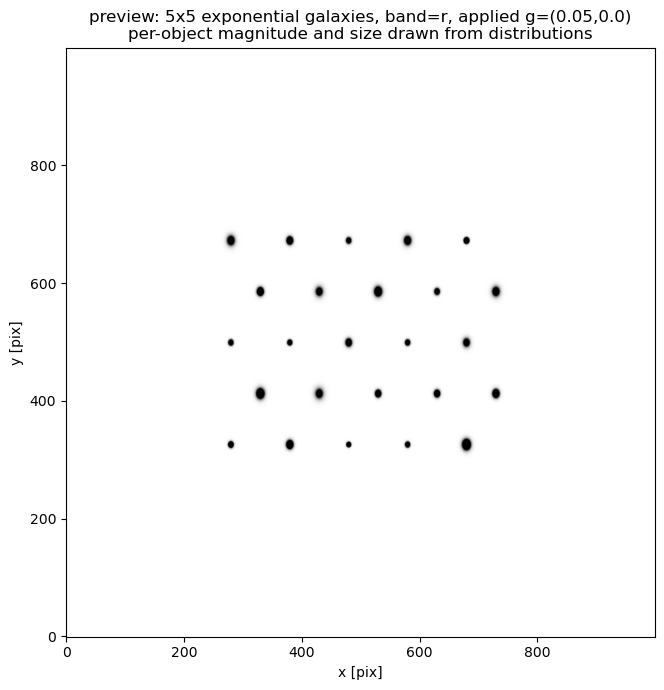

In [14]:
from imsim.utils import RUBIN_AREA

SCALE = 0.2          # arcsec/pixel
EXPTIME = 30.0       # s
PSF_FWHM = 0.7       # arcsec
band = "r"
bp = load_lsst_bandpasses()[band]
psf = galsim.Gaussian(fwhm=PSF_FWHM)

margin = 6.0 * SPACING  # arcsec padding around the grid
half = ((N - 1) * SPACING + margin) / 2.0
npix = int(2 * half / SCALE)
image = galsim.ImageF(npix, npix, scale=SCALE)
ctr = image.true_center

for o in objs:
    comps = o.get_gsobject_components(None)
    seds = o.get_observer_sed_components()
    gs = galsim.Add([comps[c] * seds[c] for c in comps])
    gs = gs.withFlux(o.get_LSST_flux(band) * EXPTIME * RUBIN_AREA, bp)
    obj = galsim.Convolve(gs, psf)
    # Tangent-plane pixel position relative to the grid center.
    dra = (o.ra - RA0) * np.cos(np.deg2rad(DEC0)) * 3600.0
    ddec = (o.dec - DEC0) * 3600.0
    x = ctr.x + dra / SCALE
    y = ctr.y + ddec / SCALE
    obj.drawImage(image=image, bandpass=bp, add_to_image=True,
                  center=galsim.PositionD(x, y))

fig, ax = plt.subplots(figsize=(7, 7))
arr = image.array
vmax = np.percentile(arr[arr > 0], 99.5)
ax.imshow(arr, origin="lower", cmap="gray_r", vmin=0, vmax=vmax)
ax.set_title(f"preview: {N}x{N} exponential galaxies, band={band}, applied g=({G1},{G2})\n"
             f"per-object magnitude and size drawn from distributions")
ax.set_xlabel("x [pix]"); ax.set_ylabel("y [pix]")
plt.tight_layout()
plt.show()

## 6. Render a single CCD with the real imSim pipeline

Run imSim's actual `LSST_CCD` pipeline (Batoid WCS, Silicon sensor, sky background) on our
catalog for one detector, using the shipped test opsim visit whose boresight we centered the
grid on. The atmospheric PSF is disabled (replaced by a simple double-Gaussian) so this runs
in a couple of minutes rather than much longer. **This cell shells out to the `galsim` CLI and
takes ~1.5-3 minutes.**

In [19]:
import imsim

IMSIM_PKG = os.path.dirname(imsim.__file__)
IMSIM_REPO = os.path.dirname(IMSIM_PKG)
TEMPLATE = os.path.join(IMSIM_PKG, "config", "imsim-config-skycat.yaml")
OPSIM_DB = os.path.join('/global/homes/b/brycek/imSim', "tests", "data", "small_opsim_9683.db")
VISIT = 449053                       # r-band visit; boresight == (RA0, DEC0)
DET_NUM, DET_NAME = 94, "R22_S11"    # central detector
imsim_out = os.path.join(OUT_DIR, NAME, "imsim_output")
os.makedirs(imsim_out, exist_ok=True)

# Build a user config that overrides the skyCatalog template (mirrors
# imSim/examples/imsim-user-skycat.yaml) to point at our catalog and this visit.
user_cfg = {
    "modules": ["imsim"],
    "template": TEMPLATE,
    "input.sky_catalog.file_name": config_path,
    "input.sky_catalog.obj_types": ["galaxy"],
    "input.atm_psf": "",                 # disable atmosphere -> much faster
    "psf": {"type": "Convolve", "items": [
        {"type": "Gaussian", "fwhm": 0.8}, {"type": "Gaussian", "fwhm": 0.3}]},
    "input.checkpoint": "",
    "input.opsim_data.file_name": OPSIM_DB,
    "input.opsim_data.visit": VISIT,
    "input.tree_rings.only_dets": [DET_NAME],
    "output.dir": imsim_out,
    "output.det_num.first": DET_NUM,
    "output.nfiles": 1,
    "output.nproc": 1,
    "image.nproc": 1,
    "image.random_seed": 42,
}
run_yaml = os.path.join(OUT_DIR, NAME, "imsim_run.yaml")
with open(run_yaml, "w") as f:
    yaml.safe_dump(user_cfg, f, sort_keys=False)

print(f"Running imSim on {DET_NAME} (a few minutes)...")
res = subprocess.run(["galsim", run_yaml, "-v1"], capture_output=True, text=True)
if res.returncode != 0:
    print(res.stdout[-1500:]); print(res.stderr[-2000:])
    raise RuntimeError("imSim run failed")
print(res.stdout.strip().splitlines()[-1])

Running imSim on R22_S11 (a few minutes)...
Done building files


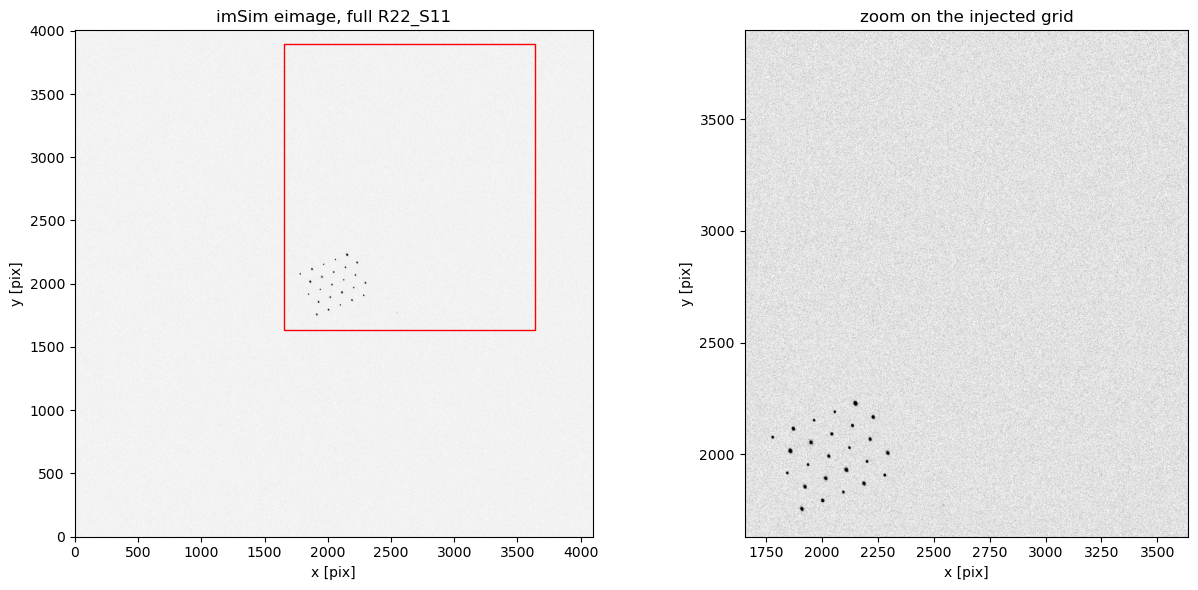

eimage: /pscratch/sd/b/brycek/grid_galaxies/catalogs/demo/imsim_output/eimage_00449053-0-r-R22_S11-det094.fits
sky median: 549.0 e-/pix


In [20]:
eimage = sorted(glob.glob(os.path.join(imsim_out, "eimage_*det094.fits")))[-1]
arr = galsim.fits.read(eimage).array
sky = np.median(arr)

# Crop to the region containing the injected sources.
ys, xs = np.where(arr > sky + 8 * arr.std())
pad = 120
y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, arr.shape[0])
x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, arr.shape[1])
crop = arr[y0:y1, x0:x1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6))
a1.imshow(arr, origin="lower", cmap="gray_r", vmin=sky, vmax=np.percentile(arr, 99.99))
a1.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, ec="red", fc="none", lw=1))
a1.set_title(f"imSim eimage, full {DET_NAME}")
a1.set_xlabel("x [pix]"); a1.set_ylabel("y [pix]")
a2.imshow(crop, origin="lower", cmap="gray_r", extent=[x0, x1, y0, y1],
          vmin=sky, vmax=np.percentile(crop, 99.9))
a2.set_title("zoom on the injected grid")
a2.set_xlabel("x [pix]"); a2.set_ylabel("y [pix]")
plt.tight_layout()
plt.show()
print(f"eimage: {eimage}\nsky median: {sky:.1f} e-/pix")

## 7. Run at scale

`run_grid_skycatalog.py` mirrors sections 1-3 as a standalone script. Each property accepts
either a float or a `scipy.stats` spec written as `"<dist>:key=val,key=val"`:
```bash
python run_grid_skycatalog.py --ra0 54.3712 --dec0 -35.8373 \
    --n 50 --spacing 15 \
    --mag "norm:loc=20,scale=0.5" --hlr "uniform:loc=0.2,scale=0.8" \
    --ellipticity 0.2 --g1 0.02 --g2 0.0 --seed 42 \
    --out-dir /sdf/data/rubin/user/brycek/grid_galaxies/catalogs --name shear_g1_0p02
```
Then render with imSim exactly as in section 6 (point `input.sky_catalog.file_name` at the
generated `skyCatalog.yaml`). To render a full focal plane, drop `output.nfiles`/`det_num.first`
so all detectors are produced, and raise `output.nproc` for parallelism.

**For an arbitrary science pointing** not in the test opsim db: either add a matching row to your
own opsim database, or replace the Batoid WCS with a plain WCS -- imSim's `sky_catalog` input
just needs `image.wcs`, `band`, and `mjd`, which need not come from opsim.

## 8. DP2 footprint coverage

`dp2_footprint_skycatalog.py` hex-tiles galaxies inside the DP2 tracts (the real survey
footprint), and can save/read tract-list files. Before generating at scale, plot the tracts
to eyeball coverage: all DP2 tracts in grey, a chosen field highlighted. Tract lists are
pre-saved under `footprints/` (regenerate with `--save-tracts`, e.g.
`python dp2_footprint_skycatalog.py --save-tracts footprints/dp2_tracts_all.txt`).

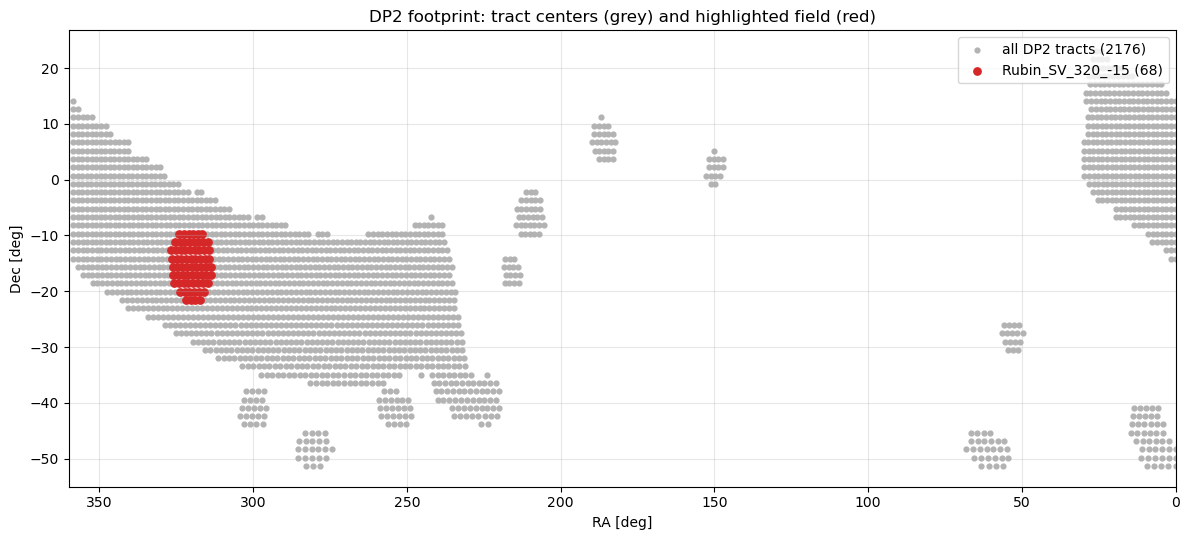

DP2 footprint: 2176 tracts, RA [0.0, 358.5], Dec [-51.3, 23.1] deg
Rubin_SV_320_-15: 68 tracts -> 6113..7995


In [18]:
FOOTPRINTS = "/global/homes/b/brycek/grid_galaxies/footprints"
ALL_TRACTS = os.path.join(FOOTPRINTS, "dp2_tracts_all.txt")
FIELD_TRACTS = os.path.join(FOOTPRINTS, "dp2_tracts_Rubin_SV_320_-15.txt")


def load_tract_centers(path):
    """Read (tract, ra, dec) columns from a saved tract-list file."""
    t, ra, dec = np.loadtxt(path, comments="#", unpack=True)
    return t.astype(int), ra, dec


_, ra_all, dec_all = load_tract_centers(ALL_TRACTS)
field_ids, ra_f, dec_f = load_tract_centers(FIELD_TRACTS)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.scatter(ra_all, dec_all, s=12, c="0.7", label=f"all DP2 tracts ({ra_all.size})")
ax.scatter(ra_f, dec_f, s=28, c="tab:red",
           label=f"Rubin_SV_320_-15 ({ra_f.size})")
ax.set_xlabel("RA [deg]"); ax.set_ylabel("Dec [deg]")
ax.set_title("DP2 footprint: tract centers (grey) and highlighted field (red)")
ax.set_xlim(360, 0)  # RA increases to the left
ax.grid(alpha=0.3); ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
print(f"DP2 footprint: {ra_all.size} tracts, "
      f"RA [{ra_all.min():.1f}, {ra_all.max():.1f}], "
      f"Dec [{dec_all.min():.1f}, {dec_all.max():.1f}] deg")
print(f"Rubin_SV_320_-15: {field_ids.size} tracts -> "
      f"{field_ids.min()}..{field_ids.max()}")